# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Alice Miller, Emma Crawford, Nina Beadnell, Maciek Romanowski**

## Setup

In [10]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    precision_recall_curve,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

This report investigates daily river water levels recorded at 392 monitoring stations across 35 counties in Scotland between 2014 and 2026. Using supervised and unsupervised machine learning techniques, we aim to identify meaningful patterns in river behaviour and investigate the potential for predicting flood events.

The data used in this report contains the river level monitoring stations (by name and by ID label), their geographical location (county of Scotland, as well as longitude and latitude) and the reported daily average, minimum and maximum water levels (in metres).

Two objectives are considered. First, clustering is used to group monitoring stations according to similarities in their water-level characteristics. Second, binary classification is used to predict whether a station will experience a flood based on observations from the preceding seven days.

Before modelling, we analyse the data for missing observations, outliers and differences in station coverage. Relevant features are then constructed to describe river properties and aid further analysis.

First, we consider clustering, an unsupervised machine learning task where, based on the constructed features, we try to group together stations with similar properties. Clustering is crucial in identifying trends, patterns and intrinsic relationships in the dataset. We implement the K-means++ and hierarchical clustering algorithms and compare their performance. We observe that all stations can be grouped into three separate groups: one containing all of the tidal stations, [input rest].

Second, we consider classification, a supervised machine learning task, where we aim to build a model to predict future flood events. We train and test various models to find the one with the best performance. Given that flood events are rare, we choose as a baseline a model which always predicts no flood. Our best performing model is [insert model].

Building on our classification model, we identify factors that can be used to predict flood events. These findings can help government agencies understand river behaviour and identify regions at high risk of flooding. By predicting floods before they occur, we aim to ease the strain on government and emergency services, and reduce the human cost of flooding [reference 1].

# Exploratory Data Analysis and Feature Engineering


Initial investigation of the data, seen in graph [Missing water-level observations across stations], indicates a significant proportion of the data is missing (30.64%). This is due to either the observation not being made, a particular observation station being decommissioned or not yet begun recording. Based on the heat map, we can see that almost no station have any recorded values before early 2017, and further analysis motivation the cut-off at [...]. We therefore decide to remove the first 908 days from out datasets.  It is also noted that the additional region of considerable missingness in 2021 is associated with the impact of Covid-19, which we kept in the dataset to maintain one continuous timeframe of investigation. Additionally we input missing dates as columns of NaNs to maintain a continuous time frame. We also ensured the dates ran in the correct chronological order. 


*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

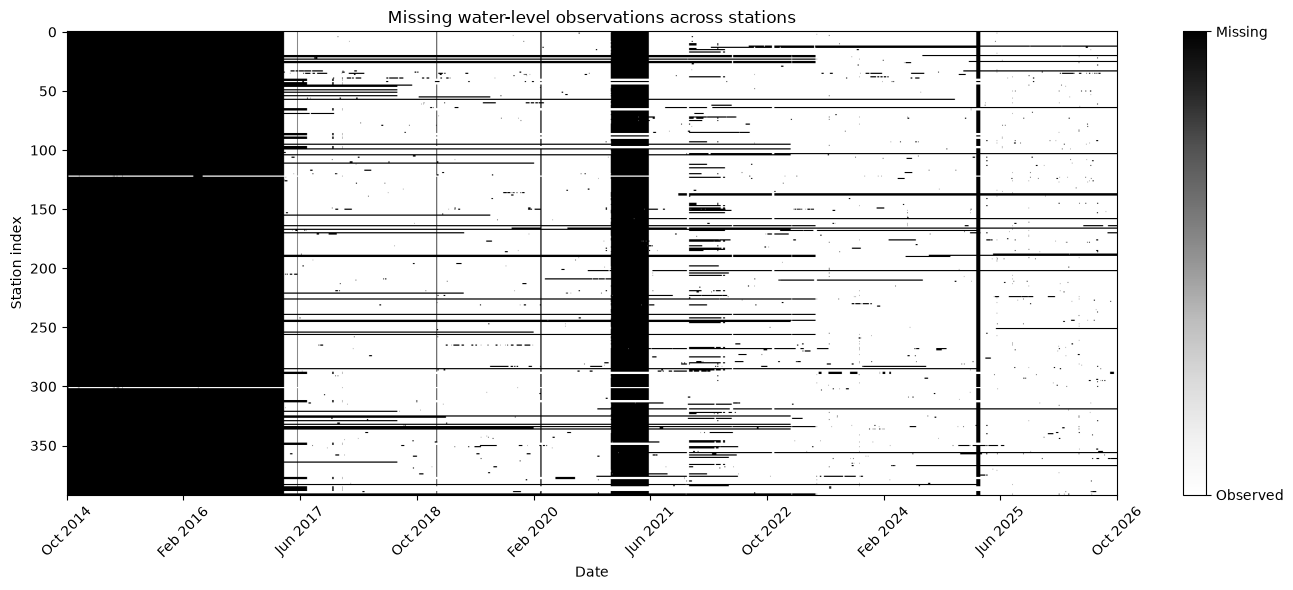

In [3]:
# Investigating the missing observations across different stations

# Select date columns
date_cols = df_avg.columns[3:]

data = df_avg[date_cols].apply(pd.to_numeric, errors="coerce")  # Make sure that the data has numerical values or NaN for missing values

# Convert columns to dates
data.columns = pd.to_datetime(date_cols, dayfirst=True)

# Sort chronologically and insert missing dates
data = data.sort_index(axis=1)

all_dates = pd.date_range(
    start=data.columns.min(),
    end=data.columns.max(),
    freq="D"
)

# If the date does NOT exist pandas creates a new column filled with NaN
data = data.reindex(columns=all_dates)

# Missing-data matrix: 1 = missing, 0 = observed
missing = data.isna().astype(int)

# Plot a heatmap
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(
    missing,
    aspect="auto",
    cmap="Greys"
)

# Date labels
ticks = np.linspace(0, len(all_dates) - 1, 10, dtype=int)

ax.set_xticks(ticks)
ax.set_xticklabels(
    all_dates[ticks].strftime("%b %Y"),
    rotation=45
)

ax.set_xlabel("Date")
ax.set_ylabel("Station index")
ax.set_title("Missing water-level observations across stations")

# Colourbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Observed", "Missing"])

plt.tight_layout()
plt.show()

We also identify "weird" values our in our data set, which could correspond to a different way of encoding missing data. Another reason for this might be the occurence of a flood event, when the equipement records abnormal values when the flood occurs. To account for this we decide to change all observation with values greater than absolute value of 30 to NaN. This allow to 


Potential outliers are present in the datasets, such as reports of river level exceeding 30m in elevation and falling below -30m, values that are simply impossible in context. This is likely due to human error, such as inputting an incorrect measure or misuse of or faulty measuring equipment. This led to the decision to ‘scrub’ these values from the data, and instead label them as no observation (NaN).

In [4]:
# Data preprocessing
def prepare_cluster(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    # Replace observations with |value| > 40 with NaN
    data = data.mask(data.abs() > 40)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(
        start=data.columns.min(),
        end=data.columns.max(),
        freq="D"
    )

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = prepare_cluster(df_avg)
minimum = prepare_cluster(df_min)
maximum = prepare_cluster(df_max)

## Feature Engineering



In [5]:
# Keep only 8-day windows where avg, min, and max all have no missing values
valid = avg.notna() & minimum.notna() & maximum.notna()
valid_8 = valid.rolling(8, min_periods=8).sum().eq(8)

# Find the date where 80% of valid windows have occurred (chronological 80/20 split)
total_valid = valid_8.sum().sum()
split = (valid_8.sum(axis=1).cumsum() >= 0.8 * total_valid).argmax() + 1

# Define floods as > 99th percentile of max water level calculated on train (before split)
thresholds = maximum.iloc[:split].quantile(0.99).dropna()
flood = maximum[thresholds.index] > thresholds
valid_flood = flood.where(valid_8[thresholds.index])

y_train = valid_flood.iloc[:split].stack().dropna().astype(int)
y_test = valid_flood.iloc[split:].stack().dropna().astype(int)

# Standardise each station using only its training mean and std (per-station Z-score)
feat_source = maximum[thresholds.index] # max water level for each station
station_mean = feat_source.iloc[:split].mean() # calculate each station's average and spread using only the training dates
station_std = feat_source.iloc[:split].std().fillna(0) + 1e-8 # add small number so doesn't crash if 0.
feat_z = (feat_source - station_mean) / station_std # Z-score

X_train_z = pd.DataFrame()
X_test_z = pd.DataFrame()

mask = valid_8[thresholds.index]

# Makes 7 separate columns: Day 1 (7 days ago) ... Day 7 (yesterday)
for i in range(1, 8):
    lag = 8 - i  # Day 1 is 7 days ago (lag=7) ... Day 7 is yesterday (lag=1)
    shifted = feat_z.shift(lag).where(mask)
    
    X_train_z[f"Day {i}"] = shifted.iloc[:split].stack().dropna()
    X_test_z[f"Day {i}"] = shifted.iloc[split:].stack().dropna()

print(f"Total valid 8-day windows: {total_valid}")
print(f"Train samples: {len(y_train)} | Floods: {y_train.sum()} ({100 * y_train.mean():.2f}%)")
print(f"Test samples:  {len(y_test)} | Floods: {y_test.sum()} ({100 * y_test.mean():.2f}%)")

Total valid 8-day windows: 1166162
Train samples: 932957 | Floods: 9535 (1.02%)
Test samples:  233205 | Floods: 2584 (1.11%)


To predict whether a flood occurs on a given day using the preceding week of observations, we first extract all consecutive 8-day periods (Days 1–7 as input features and Day 8 as the target) where daily average, minimum, and maximum levels are all present with no missing values. This gives 1166162 valid 8-day windows.   

Because water levels are time-series data, we cannot split the dataset randomly without leaking future weather patterns into the training set. Instead, we apply a chronological 80/20 train–test split based on the cumulative count of valid windows, placing the earliest 80% of periods in the training set (932957 samples) and the final 20% in the test set (233205 samples). A flood event is then defined as a Day 8 maximum water level exceeding that station's 99th percentile, calculated strictly on the training period to prevent data leakage (giving a 1.02% flood rate in training and 1.011% in testing).   

Rather than averaging the past seven days into a single summary value, we keep each preceding day as its own separate feature (Day 1 to Day 7, where Day 7 is the day immediately before the target). Averaging would obscure how recent the water levels are and whether a river is rapidly rising or receding. 

The raw water levels depend heavily on individual river depth and margin classifiers require standardised inputs. So all dimensions are measured equally. We applied per-station Z-score standardisation to the daily maximum levels using each station's training set mean and standard deviation. Every feature therefore measures how many standard deviations a river sits above or below its own normal level, placing shallow streams and deep rivers on a comparable scale without leaking test information.

# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

For a Baseline model we used always predicting a non-flood event. 

Use a SVM model...
Plotted first 5000 flood and none flood data to show why its not linear?...
therefore must use...

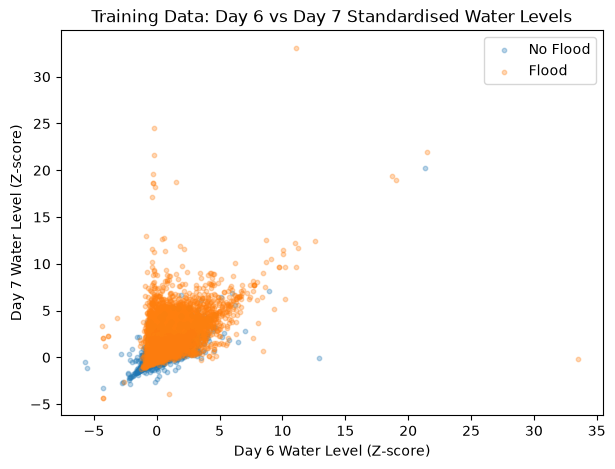

In [7]:
# Sample 5,000 non-flood days and 5,000 flood days from training so the plot is readable
no_flood_sample = X_train_z[y_train == 0].sample(5000, random_state=1)
flood_sample = X_train_z[y_train == 1].sample(5000, random_state=1)

plt.figure(figsize=(7, 5))
plt.scatter(no_flood_sample["Day 6"], no_flood_sample["Day 7"], alpha=0.3, s=10, label="No Flood")
plt.scatter(flood_sample["Day 6"], flood_sample["Day 7"], alpha=0.3, s=10, label="Flood")
plt.xlabel("Day 6 Water Level (Z-score)")
plt.ylabel("Day 7 Water Level (Z-score)")
plt.title("Training Data: Day 6 vs Day 7 Standardised Water Levels")
plt.legend()
plt.show()

## Tuning c

C = 0.001  | Mean CV Average Precision: 0.1886
C = 0.01   | Mean CV Average Precision: 0.1893
C = 0.1    | Mean CV Average Precision: 0.1894
C = 1.0    | Mean CV Average Precision: 0.1894
C = 10.0   | Mean CV Average Precision: 0.1894


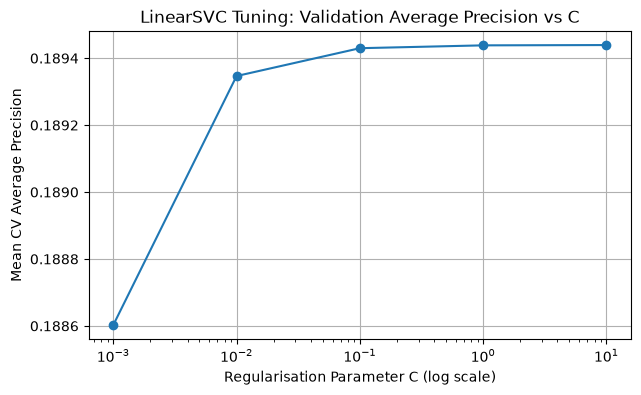

In [12]:
# Tune C on X_train_z using chronological 3-fold cross-validation
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=3)
C_values = [0.001, 0.01, 0.1, 1.0, 10.0]
mean_ap_scores = []

for c in C_values:
    svc = LinearSVC(C=c, random_state=1, max_iter=5000)
    scores = cross_val_score(svc, X_train_z, y_train, cv=tscv, scoring="average_precision")
    mean_ap_scores.append(scores.mean())
    print(f"C = {c:<6} | Mean CV Average Precision: {scores.mean():.4f}")

plt.figure(figsize=(7, 4))
plt.plot(C_values, mean_ap_scores, marker="o")
plt.xscale("log")
plt.xlabel("Regularisation Parameter C (log scale)")
plt.ylabel("Mean CV Average Precision")
plt.title("LinearSVC Tuning: Validation Average Precision vs C")
plt.grid(True)
plt.show()

To classify next-day flood events, we use a linear Support Vector Classifier (LinearSVC). Plotting a random sample of 5,000 flood and 5,000 non-flood training observations across Day 6 and Day 7 (Figure...) shows that while flood days cluster at higher Day 7 Z-scores, the two classes overlap substantially. Because the data is not linearly separable, a hard-margin Maximal Margin Classifier (MMC) cannot be used, and a soft-margin SVC is required. We use LinearSVC rather than SVC(kernel="linear") because standard kernel SVMs scale quadratically with sample size and are computationally impractical on ~933,000 training rows, whereas LinearSVC trains in quickly and yields directly interpretable feature coefficients.   

During initial exploration, we tested and rejected several alternative setups: 

- training on raw water levels in metres (which failed to account for differing river depths)
- random over-sampling and under-sampling with a non-linear RBF SVM (which either duplicated ~920,000 rows or discarded ~98% of non-flood data while triggering excessive false alarms)
- alternative 7-day summary features.

Standardising each station's 7 preceding days into Z-scores paired with LinearSVC consistently achieved the highest validation ROC-AUC and Average Precision.   

### Hyperparameter Tuning (C)

We tuned the regularisation parameter C across a logarithmic grid (0.001 to 10.0) using 3-fold TimeSeriesSplit cross-validation so that future dates never leak into past training folds. Because floods represent only ~1% of observations, we scored each fold using Average Precision (the area under the Precision-Recall curve) rather than accuracy. As shown in Figure Y, mean cross-validated Average Precision rises from 0.1886 at C = 0.001 to 0.1893 at C = 0.01, and then flattens at 0.1894 for C = 0.1, 1.0, and 10.0. Following the principle of preferring a simpler, more regularised model when validation performance is flat, we select C = 0.1 to maintain a wider margin and reduce overfitting risk.

## Threshold Selection

Model defaults to only prediciting a flood is probability greater than 50%. this is very unlikey with our data. therefore look into tuning the threshold. 

,Threshold,Recall,Precision,F1-Score,Total Alarms Triggered
0,0.01,0.7603,0.0694,0.1272,33136
1,0.02,0.5992,0.1213,0.2017,14942
2,0.03,0.5238,0.1649,0.2509,9603
3,0.05,0.4233,0.2349,0.3021,5449
4,0.08,0.3479,0.3208,0.3338,3279
5,0.10,0.3135,0.3716,0.3401,2551
6,0.15,0.2457,0.4525,0.3185,1642
7,0.25,0.1687,0.5562,0.2588,917
8,0.50,0.0678,0.6156,0.1221,333


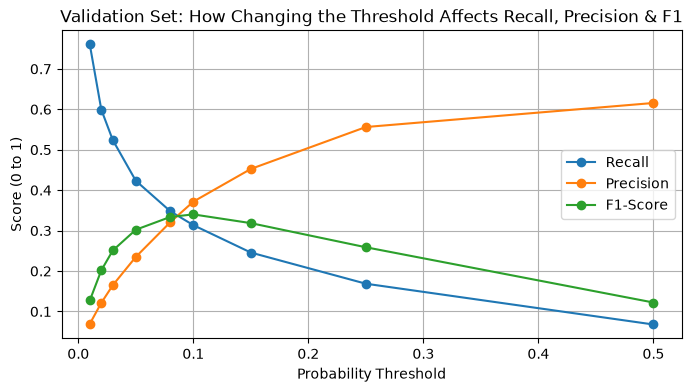

Validation F1-Optimal Threshold:    0.0914
Validation High-Recall (60%) Thresh: 0.0198


In [23]:
# the last 20% of training data chronologically is the validation slice (no test leakage)
val_cut = int(0.8 * len(X_train_z))
X_tr, y_tr = X_train_z.iloc[:val_cut], y_train.iloc[:val_cut]
X_val, y_val = X_train_z.iloc[val_cut:], y_train.iloc[val_cut:]

# Fit LinearSVC (C=0.1) with Platt scaling on the above
val_svc = CalibratedClassifierCV(
    LinearSVC(C=0.1, random_state=1, max_iter=5000),
    method="sigmoid",
    cv=3,
    ensemble=False
)
val_svc.fit(X_tr, y_tr)

# Test different probability thresholds on the validation set
test_thresholds = [0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.25, 0.50]
rows = []

for t in test_thresholds:
    # Predict Flood (1) if probability >= t, else No Flood (0)
    preds = (val_probs >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Recall": recall_score(y_val, preds),
        "Precision": precision_score(y_val, preds, zero_division=0),
        "F1-Score": f1_score(y_val, preds),
        "Total Alarms Triggered": preds.sum()
    })

thresh_df = pd.DataFrame(rows)
display(thresh_df.round(4))

# Plot how Recall, Precision, and F1 change as you move the threshold
plt.figure(figsize=(8, 4))
plt.plot(thresh_df["Threshold"], thresh_df["Recall"], marker="o", label="Recall")
plt.plot(thresh_df["Threshold"], thresh_df["Precision"], marker="o", label="Precision")
plt.plot(thresh_df["Threshold"], thresh_df["F1-Score"], marker="o", label="F1-Score")
plt.xlabel("Probability Threshold")
plt.ylabel("Score (0 to 1)")
plt.title("Validation Set: How Changing the Threshold Affects Recall, Precision & F1")
plt.legend()
plt.grid(True)
plt.show()

# validation probabilities and candidate thresholds
val_probs = val_svc.predict_proba(X_val)[:, 1]
prec, rec, thresh = precision_recall_curve(y_val, val_probs)
f1_scores = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)

best_f1_thresh = thresh[np.argmax(f1_scores)]
recall60_thresh = thresh[np.where(rec[:-1] >= 0.60)[0][-1]]  # Highest threshold that still catches >= 60% of floods

print(f"Validation F1-Optimal Threshold:    {best_f1_thresh:.4f}")
print(f"Validation High-Recall (60%) Thresh: {recall60_thresh:.4f}")

Because LinearSVC outputs hard class predictions rather than probabilities, we wrap our tuned LinearSVC(C=0.1) in CalibratedClassifierCV(method="sigmoid", cv=3, ensemble=False). This applies Platt scaling, fitting a sigmoid curve to the classifier's margin distances via 3-fold cross-validation to estimate the probability of a next-day flood for each observation. Training on the unresampled dataset allows the model to learn the true ~1% real-world flood rate rather than the artificial 50% rate induced by class balancing or resampling.

To select an appropriate decision threshold without leaking test information, we hold out the final 20% of the training set chronologically as a validation slice and evaluate thresholds ranging from 0.01 to 0.50 (Figure...). As the threshold increases, Recall drops sharply while Precision climbs steadily. At the default 0.50 cutoff, the model is overly conservative, catching fewer than 10% of validation floods. Precision and Recall intersect around 0.09, where the F1-score peaks at roughly 0.34. However, because missing an actual flood (a false negative) is far more costly than issuing a precautionary warning (a false positive), we also evaluate a lower, Recall-focused threshold of 0.03 (which catches over 50% of validation floods while maintaining ~17% precision) alongside the F1-optimal threshold of 0.09. We then refit the calibrated LinearSVC(C=0.1) on the full training set (932957 samples) for final evaluation.


Test ROC-AUC:           0.8804
Test Average Precision: 0.3251


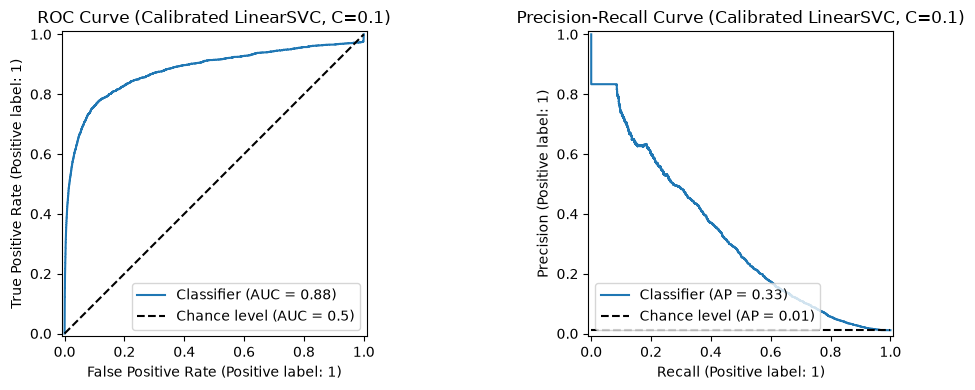

,Model / Threshold,Accuracy,Precision,Recall,F1-Score
0,Baseline (Always No Flood),0.9889,0.0000,0.0000,0.0000
1,High Recall (0.02),0.9428,0.1225,0.6745,0.2073
2,Cautious / Yellow Alert (0.03),0.9627,0.1691,0.6041,0.2643
3,Balanced / Red Alert (0.09),0.9854,0.3609,0.4106,0.3841
4,Default (0.50),0.9896,0.6714,0.1273,0.2141


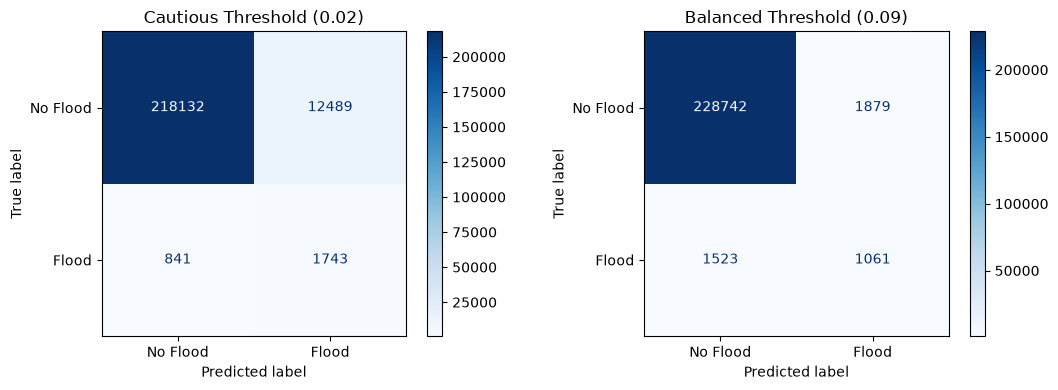

,Day,Coefficient
0,Day 1,0.0039
1,Day 2,-0.0013
2,Day 3,-0.0027
3,Day 4,-0.0012
4,Day 5,0.0028
5,Day 6,-0.0211
6,Day 7,0.0901


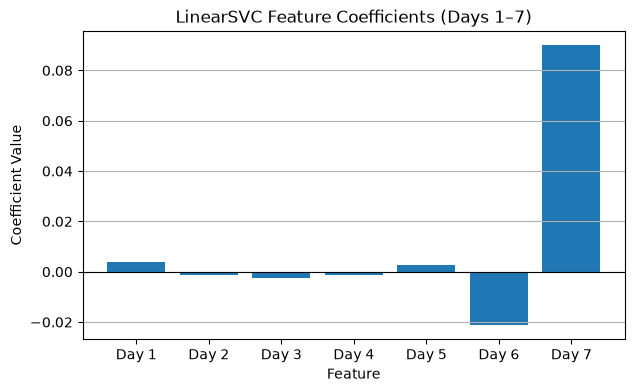

In [26]:
# Refit the final calibrated model on ALL training data (X_train_z, y_train)
final_svc = CalibratedClassifierCV(
    LinearSVC(C=0.1, random_state=1, max_iter=5000),
    method="sigmoid",
    cv=3,
    ensemble=False
)
final_svc.fit(X_train_z, y_train)

# Baseline ("Always No Flood")
baseline = DummyClassifier(strategy="constant", constant=0)
baseline.fit(X_train_z, y_train)
y_pred_base = baseline.predict(X_test_z)

# Predict flood probabilities on the test set
y_probs = final_svc.predict_proba(X_test_z)[:, 1]
print(f"Test ROC-AUC:           {roc_auc_score(y_test, y_probs):.4f}")
print(f"Test Average Precision: {average_precision_score(y_test, y_probs):.4f}")

# Plot ROC Curve and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_test, y_probs, plot_chance_level=True, ax=axes[0])
axes[0].set_title("ROC Curve (Calibrated LinearSVC, C=0.1)")

PrecisionRecallDisplay.from_predictions(y_test, y_probs, plot_chance_level=True, ax=axes[1])
axes[1].set_title("Precision-Recall Curve (Calibrated LinearSVC, C=0.1)")
plt.tight_layout()
plt.show()

# Compare Baseline vs. Candidate Thresholds on Test Set
rows = [{
    "Model / Threshold": "Baseline (Always No Flood)",
    "Accuracy": accuracy_score(y_test, y_pred_base),
    "Precision": precision_score(y_test, y_pred_base, zero_division=0),
    "Recall": recall_score(y_test, y_pred_base),
    "F1-Score": f1_score(y_test, y_pred_base)
}]

for name, t in [
    ("High Recall (0.02)", 0.02),
    ("Cautious / Yellow Alert (0.03)", 0.03),
    ("Balanced / Red Alert (0.09)", 0.09),
    ("Default (0.50)", 0.50),
]:
    preds = (y_probs >= t).astype(int)
    rows.append({
        "Model / Threshold": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds),
        "F1-Score": f1_score(y_test, preds)
    })

display(pd.DataFrame(rows).round(4))

# Plot Confusion Matrices side-by-side (0.03 vs 0.09)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, (y_probs >= 0.02).astype(int),
    display_labels=["No Flood", "Flood"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Cautious Threshold (0.02)")

ConfusionMatrixDisplay.from_predictions(
    y_test, (y_probs >= 0.09).astype(int),
    display_labels=["No Flood", "Flood"], cmap="Blues", ax=axes[1]
)
axes[1].set_title("Balanced Threshold (0.09)")
plt.tight_layout()
plt.show()

# Plot the 7 Feature Coefficients
weights = final_svc.calibrated_classifiers_[0].estimator.coef_[0]
coef_df = pd.DataFrame({"Day": X_train_z.columns, "Coefficient": weights})
display(coef_df.round(4))

plt.figure(figsize=(7, 4))
plt.bar(coef_df["Day"], coef_df["Coefficient"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("LinearSVC Feature Coefficients (Days 1–7)")
plt.xlabel("Feature")
plt.ylabel("Coefficient Value")
plt.grid(axis="y")
plt.show()

We evaluate our final model once on the untouched chronological test set (233,205 observations; 2,584 floods, or 1.11%) and compare it against the group's baseline model (DummyClassifier, which always predicts "No Flood").

Baseline Performance: Always predicting "No Flood" achieves 98.89% accuracy simply because non-flood days dominate the dataset, but scores 0.0 for Precision, Recall, and F1-score showing that accuracy alone is misleading under severe class imbalance.

Ranking Performance (ROC and Precision-Recall Curves): Across all thresholds (Figure...), our calibrated LinearSVC achieves a test ROC-AUC of 0.8804 and an Average Precision (AP) of 0.3251. Compared to a random classifier, the model demonstrates strong ability to rank high-risk flood days above normal days.

Threshold Trade-offs and Confusion Matrices: Table... and Figure... compare the baseline against our model across candidate thresholds:

At the High-Recall threshold (0.02), the model achieves 0.6745 Recall and 0.1225 Precision (F1 = 0.2073), correctly identifying 1743 floods with 12489 false alarms.

At the Balanced threshold (0.09), the model achieves 0.4106	 Recall and 0.3609 Precision (F1 = 0.3841), correctly identifying 1061 floods while keeping false alarms down to 1879 out of 230,621 normal days

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

* Summarise cluster findings

## What Drives Flood Predictions (Feature Interpretation)

An advantage of a linear classifier on standardised inputs is that its coefficients can be compared directly to see which days drive flood risk (Figure...):

Yesterday's water level (Day 7, coefficient = 0.0901): This is the strongest positive driver in the model. The further a river sits above its normal level for yesterday, the higher the probability of exceeding its 99th-percentile flood threshold today.

Two days prior (Day 6, coefficient = -0.0211): Notably, Day 6 carries a negative weight alongside the large positive weight on Day 7. This means the model has automatically learned to detect rapidly rising water levels. A river that is high on Day 7 after being much lower on Day 6 (a sharp 48-hour surge) signals a much higher flood risk than a river that was already high on Day 6 and is now stabilising or draining back down.

Earlier in the week (Day 1 to Day 5, coefficients between 0.0039 and 0.0028): Water levels from three to seven days earlier have weights close to zero, indicating that once the last 48 hours of river behaviour are known, older readings add very little predictive value. This also explains why simpler 7-day averages underperform: averaging smooths out both recency and the critical 48-hour rate of rise.

## Practicalities

Because our model outputs calibrated flood probabilities rather than a binary yes/no decision, agencies can tailor alerts to operational priorities without retraining the model. Therefore a tiered alert framework could be used.

Precautionary ("Yellow") Alert (threshold = 0.02): Prioritises catching a higher share of upcoming floods to prompt early internal monitoring and preparedness, accepting a moderate rate of false alarms.

High-Confidence ("Red") Alert (threshold = 0.09): Balances flood detection with higher alert reliability, helping prevent "warning fatigue" among emergency services and the public.

## Limitations

* Absence of meteorological data: The model relies solely on past river levels and has no access to rainfall measurements, Met Office weather forecasts, snowmelt, or soil saturation. When an intense overnight storm hits a dry catchment, a flash flood can occur with no prior signal in the previous seven days—accounting for a large share of the model's missed floods.
* Proxy flood definition: Defining a flood statistically as the top 1% of each station's training-set maximum levels ensures consistency across 392 stations, but it does not directly measure whether water breached riverbanks or caused property damage.
* Data gaps and sensor anomalies: Roughly 30.6% of the raw dataset was missing (including an extended gap during 2021 linked to Covid-19), and extreme readings exceeding $\vert{}40\vert{}\text{ m}$ had to be scrubbed as sensor errors. Removing windows with missing days may exclude periods where extreme floods themselves damaged gauging equipment.
* Uniform linear model across river types: A single global LinearSVC tidal estuaries, slow-draining lowland rivers, and flashy upland streams using the same 7-day weights, even though our clustering analysis shows these stations behave very differently [reference?].

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [8]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] ERROR | Error while converting 'project.ipynb'
Traceback (most recent call last):
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\nbconvertapp.py", line 487, in export_single_notebook
    output, resources = self.exporter.from_filename(
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\templateexporter.py", line 386, in from_filename
    return super().from_filename(filename, resources, **kw)  # type:ignore[return-value]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\exporter.py", line 201, in from_filename
    return self.from_file(f, resources=resources, **kw)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Maciek\anaconda3\Lib\site-packages\nbconvert\exporters\templateexporter.py", line 392, in from_file
    return su